# CNN Multi-class Classification

We can follow the same steps we followed in the previous sections:

- Load the Data.
- Preprocess the data.
- Create a model.
- Fit the model.
- Evaluate.
- Try to improve the model by fine tuning different parts of it.


So, first loading the data.

Just like before I've already made a split of the `food 101` dataset and randomly selected 10 classes. You can run the following code to download the whole zip and decompress it.

In [1]:
# !wget "https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/raw/refs/heads/main/4_Convolutional_Neural_network/resource/10FoodClasses.zip"

# import zipfile

# zip_ref = zipfile.ZipFile('10FoodClasses.zip')
# zip_ref.extractall(path='resource')
# zip_ref.close()

Now Let's take a look at the `10FoodClasses` folder like before

In [2]:
import os

for dirpath, dirnames, filenames in os.walk('resource/10FoodClasses'):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

There are 2 directories and 0 images in 'resource/10FoodClasses'.
There are 10 directories and 0 images in 'resource/10FoodClasses/train'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/chicken_wings'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/tiramisu'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/hamburger'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/mussels'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/cannoli'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/chocolate_cake'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/bread_pudding'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/ramen'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/miso_soup'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/creme_brulee'.
There are 10 d

Alright! 800 images in each food class in the training set and 200 images in each food class in the validation set. 

You might ask where is the testing set.

It's the same thing, to be honest. Validation set is used to see performance on the unseen data while training the model and testing set is used to see performance on the unseen data after the model is trained.

Both are unseen datasets. So, We can use it interchangeably.

I'll be using `val` set for both validation and testing.

So, let's load the data.

In [3]:
from keras.utils import image_dataset_from_directory    

training_set = image_dataset_from_directory(
    directory='resource/10FoodClasses/train',
    batch_size=24,
    image_size=(224, 224),
    shuffle=True,
    seed=42
)

validation_set = image_dataset_from_directory(
    directory='resource/10FoodClasses/val',
    batch_size=24,
    image_size=(224, 224),
    shuffle=False,
)

2026-10-23 19:10:48.110313: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Found 2500 files belonging to 10 classes.


I0000 00:00:1792761050.017801  306141 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9622 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:05:00.0, compute capability: 8.6


Found 500 files belonging to 10 classes.


Wow, now we have 10000 images,(I just hope my pc stays alive). 

So, let's do this.

What classes do we have?

In [4]:
training_set.class_names

['bread_pudding',
 'cannoli',
 'chicken_wings',
 'chocolate_cake',
 'creme_brulee',
 'hamburger',
 'miso_soup',
 'mussels',
 'ramen',
 'tiramisu']

So, nice diverse classes.

So, let's make a model. This time we have to keep in my our model have to predict `10 classes` instead of just 2. So, the model outpput layer will be a little different.

If you don't know about multi-class classification, you can read one of the previous [article on multi-class classification](https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/blob/main/pdfs/5_Multi_Class_Classification.pdf)

Mainly there onely one thing we have to do.

- The number of neurons in the output layer must be equal to the number of classes.

and the activation function for the output layer will be `softmax` instead of `sigmoid`.

So, let's make a model.

In [5]:
from keras import layers, activations, models


model4 = models.Sequential([
    layers.Input((224,224,3)),    
    layers.Rescaling(1./255),

    layers.Conv2D(10, (3,3), activation='relu'),
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((4,4)),
    layers.Flatten(),
    
    layers.Dense(5, activation='relu'),
    layers.Dense(10, activation=activations.softmax)
])

model4.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 110, 110, 10)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 26, 26, 10)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6760)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        33,805 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,875 (144.04 KB)

 Trainable params: 36,875 (144.04 KB)

 Non-trainable params: 0 (0.00 B)

Model 4 is basically `model 3` with the output layer changed to fit our requirement.

As this model was performing pretty good on cheesecake and pizza dataset. Let's how good it handles 10 food classes.

So, let's compile and fit the model.

In [6]:
from keras import optimizers, losses, metrics

model4.compile(
    optimizer=optimizers.Adam(),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

Now, I'll use 50% the validation set as validation data whole the model is training we can do that by setting `validation_split` to 0.5.

> 

In [7]:
model4.fit(
    training_set,
    epochs=50,
    validation_data=validation_set,
)

Epoch 1/50


/home/itvaya/miniforge3/envs/ml_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-23 19:10:52.273795: I external/local_xla/xla/service/service.cc:163] XLA service 0x7953b400c990 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-23 19:10:52.273814: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3060, Compute Capability 8.6
2026-10-23 19:10:52.319904: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-23 19:10:52.482243: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90300

 13/105 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.3091 - sparse_categorical_accuracy: 0.1026

I0000 00:00:1792761057.666628  306211 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 2.3036 - sparse_categorical_accuracy: 0.0956

2026-10-23 19:11:03.576071: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_126', 172 bytes spill stores, 172 bytes spill loads

2026-10-23 19:11:03.646913: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_126', 192 bytes spill stores, 192 bytes spill loads



105/105 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - loss: 2.3036 - sparse_categorical_accuracy: 0.0956 - val_loss: 2.3052 - val_sparse_categorical_accuracy: 0.0980
Epoch 2/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 2.3028 - sparse_categorical_accuracy: 0.0956 - val_loss: 2.3029 - val_sparse_categorical_accuracy: 0.0920
Epoch 3/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 2.2951 - sparse_categorical_accuracy: 0.1208 - val_loss: 2.2714 - val_sparse_categorical_accuracy: 0.1400
Epoch 4/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 2.2662 - sparse_categorical_accuracy: 0.1496 - val_loss: 2.2285 - val_sparse_categorical_accuracy: 0.1720
Epoch 5/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2.2104 - sparse_categorical_accuracy: 0.1840 - val_loss: 2.1692 - val_sparse_categorical_accuracy: 0.2020
Epoch 6/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 2.1718 - sparse_categorical_accuracy: 0.2044 - val_loss: 2.1276 - val_sparse_categorical_accuracy: 0.2220
Epoch 7/

<Axes: >

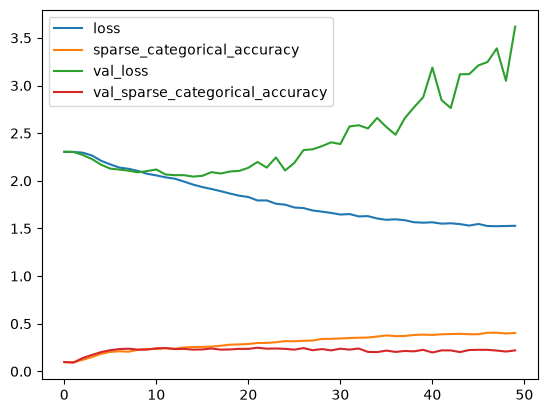

In [8]:
import pandas as pd

pd.DataFrame(
    model4.history.history
).plot()